# Regularized linear regression

## What will you learn in this course? 🧐🧐

This course teaches you two variations of the linear regression model, called regularized regressions.

* What is regularization?
* Ridge model
    * What is a cost/loss function?
    * Bias vs Variance
    * Ridge model penalty
    * Special case of the intercept
* Lasso model
     * Why does the linear model fail?
     * How can we overcome this difficulty?
         * Variable selection problem
     * The Lasso model
         * Intuition
         * Lasso estimator
* Underfitting and overfitting
     

## What is regularization? 👮

Regularization is a principle widely used in statistics and machine learning. It constrains models to adopt certain behaviours. Here, it lets us:

* reduce the importance of explanatory variables that do not bring relevant information to the model, or remove them altogether;
* deal with problems where there are many more explanatory variables than observations.

Linear models are popular for estimating a continuous target variable $Y$ that depends on explanatory variables $X_{1}, X_{2}, ... , X_{p}$. In general, the number of observations (or samples, often noted $n$) is much greater than the number of explanatory variables $p$. Sometimes, however, it is the opposite: there are many more explanatory variables than observations. Statistical genetics is a good example: time and money constraints rarely let researchers sequence the DNA of more than a thousand individuals, while our DNA contains about 20,000 genes! Classical linear models are not well suited to such high-dimensional problems. In this course, we will see variations of linear models that can tackle this difficulty.


## Ridge model - `L2` Regularization 🌉

### What is a cost function? 💸

The **cost function** is a concept you will use again and again: it is everywhere in machine learning. It is the mathematical quantity we want to minimize when we fit a statistical model. In classical multiple linear regression, the cost function is:

$$
||y-X^{t}\beta||^{2}_{2}
$$

This is the squared Euclidean norm of the error vector (the Euclidean norm of a vector is the square root of the sum of its squared components). In other words, it is the sum of the squared errors, which is the Mean Squared Error multiplied by $n$. The estimator $\beta$, which gives the coefficients of the model, is the vector that minimizes this cost function. Mathematically:

$$
\beta^* = argmin_{\beta}(||y-X^{t}\beta||^{2}_{2})
$$

This cost function gives an estimator with no bias. But its predictions can have a high variance, especially when there are many explanatory variables. Sometimes, a better compromise can be found.

This is why we introduce the notion of **penalty**: a modification of the cost function that controls the **bias vs. variance** trade-off.

### Bias vs Variance

Bias and variance are two key notions in statistics, and especially in machine learning when we try to make predictions.

Let's consider a problem where $Y$ is the target variable, $X$ is the matrix of explanatory variables and $\epsilon$ is an error term with mean 0 and variance $\sigma^2$.

We want to model $Y$ using the explanatory variables $X$. We assume that there is a function $f$ that represents the true relationship between $Y$ and $X$, such that:

$$
Y=f(X)+\epsilon
$$

At the end of our work as data scientists, we obtain an estimate $\widehat{f}$ of the function $f$. The mean squared error (often noted MSE) of this estimate can then be split into a bias term (the average deviation from the true function) and a variance term (how much the estimator spreads around its own mean). This decomposition is written as follows:

$$
E[(Y-\widehat{f})^2]=E[f-\widehat{f}]^2+E[\hat{f}^2]-E[\widehat{f}]^2+\sigma^2
$$

$$
E[(Y-\widehat{f})^2]=bias^2+variance+\sigma^2
$$

The bias measures how far the average prediction is from the true function $f$, the variance measures how much the predictions vary, and $\sigma^2$ is the part of $Y$ that no model can explain, also called noise.

### Ridge model penalty

The Ridge model is a penalized version of the multiple linear model whose cost function is:

$$
||y-X^{t}\beta||^{2}_{2}+\lambda||\beta||^{2}_{2},\lambda\in\mathbb{R^{+*}}
$$ 

With this penalty, changing the parameters $\beta$ may improve the fit (the first term), but larger parameters also increase the second term, the penalty. So the model has to make choices: it gives large parameters only to the explanatory variables that carry the most relevant information about the target variable, and keeps the parameters of less relevant variables close to zero.

In terms of bias vs. variance trade-off, the Ridge model behaves as follows:

* $\lambda = 0$ corresponds to the ordinary linear model, with maximal variance (and the closest fit to the training data)
* Bias increases as $\lambda$ increases
* Variance decreases as $\lambda$ increases
* $\lambda = \infty$ corresponds to the model where all the parameters are zero, hence $\beta_i = 0 \forall i \neq 0$ and the estimator is $\bar{Y}$ (the average of the $Y$ values). This is the model with the lowest possible variance.

### Special case of the intercept

The intercept is the parameter $\beta_0$ of the model. It is not associated with any explanatory variable: it is the estimated mean level of $Y$ when all the explanatory variables are 0. That is why, in practice, it is not penalized. The cost function of the Ridge model with intercept is therefore:

$$
||y-\beta_0-X^{t}\beta||^{2}_{2}+\lambda||\beta||^{2}_{2},\lambda\in\mathbb{R^{+*}}
$$

## Lasso model - `L1` Regularization 🪢

### Why does the linear model fail?

As we saw earlier, the linear model is written as follows:

$$
Y_i = \beta_0 + X_{i,1}\beta_1 + ... + X_{i,p}\beta_p + \epsilon_i \forall_i \in[\![1,n]\!]
$$

Or in matrix form:

$$
Y=X^{t}\beta+\epsilon
$$

If $p > n$, the first form gives $n$ equations with $p + 1$ unknown parameters $\beta_0,\beta_1,...,\beta_p$. But a system with more unknowns than independent equations is underdetermined: it has an infinite number of solutions.

In matrix form, $X^{t}X$ is a $p*p$ matrix, but its rows and columns are linear combinations of only $n$ vectors. So its rank is at most ***n*** $< p$: the matrix is not invertible, and the parameters cannot be estimated.

### How can we overcome this difficulty?

#### Variable selection problem

As we have seen, the Ridge model works well when some explanatory variables are not very informative, because it shrinks their coefficients. But sometimes the true value of many coefficients is 0, i.e. the corresponding explanatory variables have no influence on the target variable. Ridge does not penalize these uninformative variables enough: it shrinks their coefficients, but never sets them exactly to zero. So Ridge cannot be used for variable selection.

That is why another model, called Lasso, exists: it selects the relevant variables and sets the coefficients of the useless variables to zero.

### The Lasso model

#### Intuition

The key intuition behind the Lasso model is that many of the available explanatory variables have no influence on the target variable. Their coefficients would therefore have a true value of 0 in the linear model.

Let $n$ be the number of observations, $p$ the number of explanatory variables and $s$ the number of relevant explanatory variables. Mathematically, this intuition (called the **sparsity** hypothesis) is written as follows:

$$
s<<n<<p
$$

> 👋 $<<$ means *much less than*

By keeping only the $s$ relevant variables, we hope to end up in a situation where the linear model can be applied without difficulty.

Mathematically, we wish to find $\beta$ that minimizes the following cost function:

$$
\widehat{\beta_n}=arg\min_{\beta:||\beta||_{0}\leq{s}}||Y-X^{t}\beta||^{2}_{2}
$$

This equation means that $\widehat{\beta_n}$ is the vector that minimizes $||Y-X^{t}\beta||^{2}_{2}$, under the constraint that $\beta$ has at most $s$ non-zero elements.

Here, $||\:||_{0}$ is the "zero norm": it counts the number of non-zero elements in $\beta$.

However, this constraint is very hard to optimize, because it does not define a convex set. Instead, we use a weaker constraint that gives a convex cost function. It is based on the "L1 norm" $||\:||_{1}$, defined as the sum of the absolute values of the components of a vector.

#### Lasso estimator

Here we introduce the _Least Absolute Shrinkage and Selection Operator_ (LASSO), defined by the following cost function:

$$
||Y-X^{t}\beta||^{2}_{2}+\lambda||\beta||_{1}
$$

Here is what you need to know about the LASSO model:

* $\lambda$, the penalty constant, must be chosen carefully. In general, LASSO solvers use cross-validation (explained in the next lesson): they compute the estimator for many values of $\lambda$ to find the most relevant ones.
* The higher $\lambda$, the sparser the solution $\hat{\beta}_{LASSO}$ (i.e. it contains few non-zero elements), the higher the bias and the lower the variance.
* The smaller $\lambda$, the more non-zero coefficients. This decreases the bias of the model but can dramatically increase the variance (this is called overfitting).
* In practice, you will soon discover that the bias introduced by LASSO can be very large. If you need precise results, you can use LASSO to select the best variables, then fit a plain linear model on these variables only to remove this bias.

## Underfitting and Overfitting

Two notions were mentioned above. Here is what they mean:

* **Underfitting** happens when a model is too simple to give a good estimate of the target variable.
* **Overfitting** is the opposite: a model so complex that it fits the training data too well. Such a model is useless in practice, because it is very unlikely to generalize well to new, unseen data.

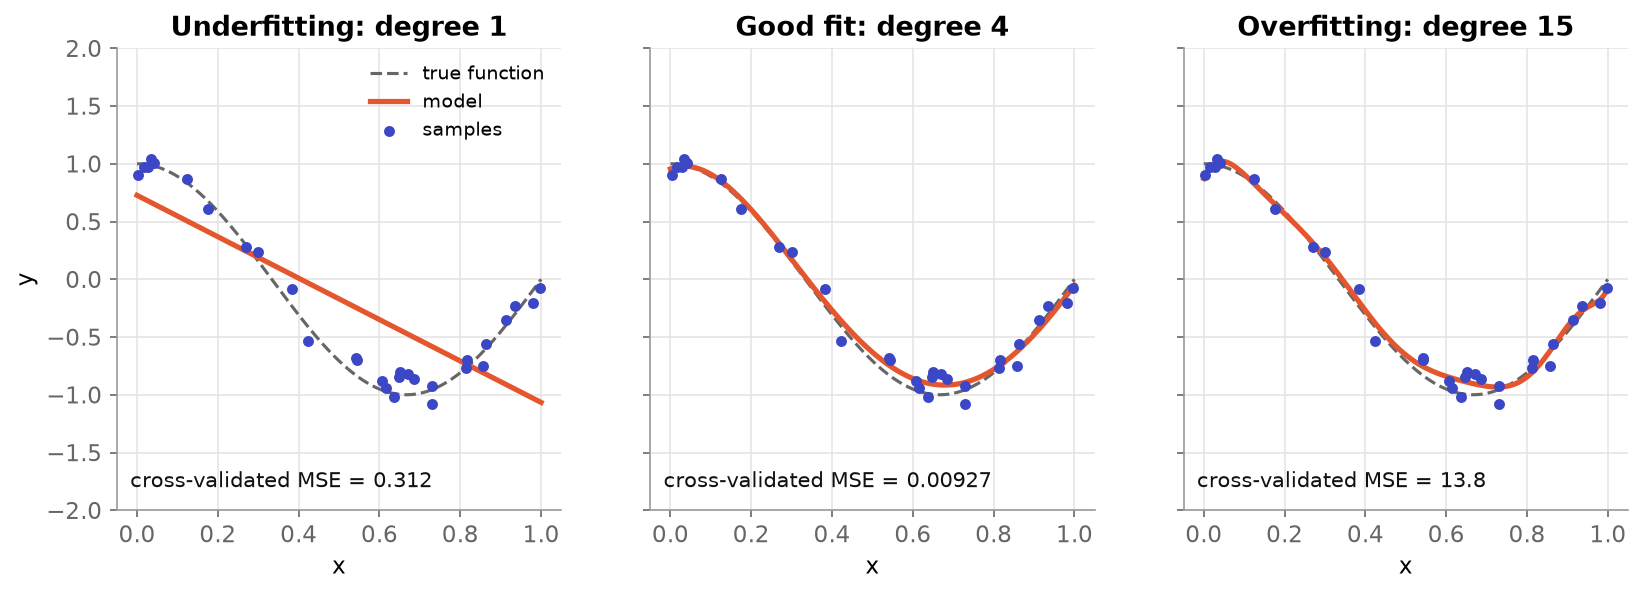

The figure above shows, from left to right, underfitting, a good fit, and overfitting.


## Resources 📚📚

* [Ridge Regression and classification](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification)

* [Lasso](https://scikit-learn.org/stable/modules/linear_model.html#lasso)

* [L1 and L2 Regularization](https://towardsdatascience.com/l1-and-l2-regularization-methods-ce25e7fc831c)